In [1]:
from pathlib import Path
import os
import sys

# 无论从仓库根目录还是 notebook 目录启动，都统一回到仓库根目录。
repo_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'factors').is_dir() and (path / 'data').is_dir()
)
os.chdir(repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

%load_ext autoreload
%autoreload 2

# 仓单变化单因子实验 `ReceiptChange`

本实验固定使用 **2018-01-02 至 2024-12-31** 的主面板与品种-交易日聚合仓单数据（CZCE 仓单自 2018-01-02 起才可获取，更早样本会造成截面在交易所之间不可比），以 `market_rank_ls` 诊断组合评价参数扫描。

参数只围绕经济机制展开：

- `lookback ∈ {5, 10, 20, 40, 60}`：仓单流量窗口，从一周到约一个季度。仓单注册/注销是"可交割供给冲击"的直接代理，窗口长短对应冲击被市场消化的速度；
- `ffill_limit ∈ {0, 5}`：对仓单发布缺口的容忍度。0 表示只在真实发布日有值（严格因果、无伪造），5 表示最多向前填充 5 个交易日（默认值，把偶发漏报补齐，但可能伪造出并不存在的"仓单水平不变"）；
- `h = 5, 10, ..., 60`：持有期。

共 10 个因子变体 × 12 个持有期 = 120 个扫描候选；每个候选在 10 个调仓锚点相位（`offset 0-9`）上各运行一次诊断组合并对 Sharpe / CAGR 取平均（共 1200 次运行），扫描用 joblib 8 进程并行。相位平均是为了在参数面上直接压掉单锚点带来的调仓时点运气（rebalance timing luck）。`ReceiptChange` 计算开销极低（对数差分），每个变体只 `compute` 一次，因子值在 12 个持有期之间复用。

In [2]:
from collections.abc import Mapping
from contextlib import redirect_stdout
from dataclasses import replace
from typing import Any
import datetime
import io
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from factors import presets
from factors.diagnostic_portfolio import DiagnosticPortfolioExperimentRunner
from factors.exploration import xray
from factors.library.others.future_native.delivery import ReceiptChange
from factors.models import DataRequirement
from factors.scanning import (
    EvaluationResult, gen_candidate_grid, run_scan,
)

# notebook 需要推送到 GitHub：控制图片像素体积，够看清即可。
plt.rcParams['figure.dpi'] = 95
plt.rcParams['savefig.dpi'] = 95

## 构造研究数据集

In [3]:
start_date = datetime.date(2018, 1, 2)
end_date = datetime.date(2024, 12, 31)

# 数据管理器会逐品种打印缓存加载信息；这里只保留实验摘要。
with redirect_stdout(io.StringIO()):
    dataset, facade = presets.build_dataset_with_facade(
        start_date=start_date,
        end_date=end_date,
        sources=(
            DataRequirement(source='main_panel'),
            DataRequirement(
                source='warehouse_receipt',
                columns=('trading_date', 'product', 'receipt_quantity'),
                request_params={'aggregate': True},
            ),
        ),
    )

assert dataset.auxiliary is not None
warehouse = dataset.auxiliary['warehouse_receipt']
factor_data = {
    'main_panel': dataset.main_panel,
    'warehouse_receipt': warehouse,
}
panel_products = dataset.main_panel.index.get_level_values('product').nunique()
receipt_products = warehouse['product'].nunique()
print(f'主面板：{len(dataset.main_panel):,} 行，{panel_products} 个品种')
print(f'仓单聚合：{len(warehouse):,} 行，{receipt_products} 个品种')
print(f'仓单区间：{warehouse["trading_date"].min():%Y-%m-%d} '
      f'至 {warehouse["trading_date"].max():%Y-%m-%d}')
print(f'样本区间：{start_date} 至 {end_date}')

主面板缺品种提醒：以下品种数据引擎返回了空 DataFrame。在主面板中会缺失：['AD', 'BZ', 'ER', 'ME', 'OP', 'PD', 'PL', 'PT', 'RO', 'TC', 'WS', 'WT']


主面板：115,112 行，82 个品种
仓单聚合：91,394 行，70 个品种
仓单区间：2018-01-02 至 2024-12-31
样本区间：2018-01-02 至 2024-12-31


## 参数空间与因子预计算

10 个变体 = 5 个 `lookback` × 2 个 `ffill_limit`。每个变体只 `compute` 一次；`ReceiptChange` 输出索引覆盖品种在主面板上的完整交易日网格（含 NaN 行），因此覆盖率能如实反映"仓单数据是否可得"。

按交易所分组看覆盖率是有必要的：DCE 少数品种（如 P、J）到 2021 年前后才稳定日频，CZCE 自 2018 年起才有数据，直接混在一个截面里比较时要把"数据可得性"和"机制强弱"区分开。

In [4]:
LOOKBACKS = [5, 10, 20, 40, 60]
FFILLS = [0, 5]

# 品种 -> 交易所 映射，用于分组覆盖率统计。
universe = facade.rule_query.get_product_universe(return_type='dict')
exchange_map = {p: meta['exchange'] for p, meta in universe.items()}

factor_values: dict[str, pd.Series] = {}
diagnostics: list[dict[str, Any]] = []

# 因子逐品种记录警告会刷屏；预计算期间只保留错误级别日志。
factor_logger = logging.getLogger(
    'factors.library.others.future_native.delivery')
previous_level = factor_logger.level
factor_logger.setLevel(logging.ERROR)
try:
    for lookback in LOOKBACKS:
        for ffill_limit in FFILLS:
            variant = f'l{lookback}_ff{ffill_limit}'
            factor = ReceiptChange(lookback=lookback, ffill_limit=ffill_limit)
            values = factor.compute(factor_data)
            factor_values[variant] = values
            diagnostics.append({
                'variant': variant,
                'lookback': lookback,
                'ffill_limit': ffill_limit,
                'valid_count': int(values.notna().sum()),
                'coverage': float(values.notna().mean()),
                'warning_count': int(getattr(
                    factor, '_warning_count', len(factor.warnings))),
            })
finally:
    factor_logger.setLevel(previous_level)

diagnostics_table = pd.DataFrame(diagnostics).set_index('variant')
assert len(factor_values) == 10
display(diagnostics_table.style.format({'coverage': '{:.2%}'}))

,lookback,ffill_limit,valid_count,coverage,warning_count
variant,,,,,
l5_ff0,5,0,87309,84.26%,2
l5_ff5,5,5,91385,88.20%,2
l10_ff0,10,0,86299,83.29%,2
l10_ff5,10,5,90255,87.11%,2
l20_ff0,20,0,85655,82.67%,2
l20_ff5,20,5,89397,86.28%,2
l40_ff0,40,0,84143,81.21%,2
l40_ff5,40,5,87848,84.78%,2
l60_ff0,60,0,82753,79.87%,3


## 代表信号分布

以 `l20_ff5`（约一个月流量窗口、默认填充）为代表，先体检分布，再看分交易所与分品种的覆盖率；同时与 `l20_ff0`（不填充）对比，观察 `ffill_limit` 对有效样本量的影响。

Summary Statistics of receipt_change_l20_ff5
count    89397.000000
mean        -0.010798
std          1.995864
min        -11.708533
1%          -7.601402
25%         -0.192624
50%          0.000000
75%          0.209235
99%          7.699027
max         11.733762
Percentage of 0: 17.22%
Percentage of NaN: 13.72%; total length=103616
N unique values: 49942
Percentage of positive: 35.44%
Percentage of negative: 33.62%

分交易所覆盖率（l20_ff5）：


,count,mean,median,min
exchange,,,,
CZCE,2500.00%,89.97%,98.82%,29.49%
DCE,2100.00%,69.24%,73.51%,4.00%
GFEX,200.00%,70.04%,70.04%,68.18%
INE,400.00%,92.43%,92.15%,90.21%
SHFE,1800.00%,95.94%,98.82%,72.33%


覆盖率最低的 10 个品种：


,coverage,exchange
product,,
BB,4.00%,DCE
JM,12.12%,DCE
RR,29.37%,DCE
WH,29.49%,CZCE
B,32.43%,DCE
JD,40.49%,DCE
LH,50.47%,DCE
PX,59.29%,CZCE
SH,59.29%,CZCE


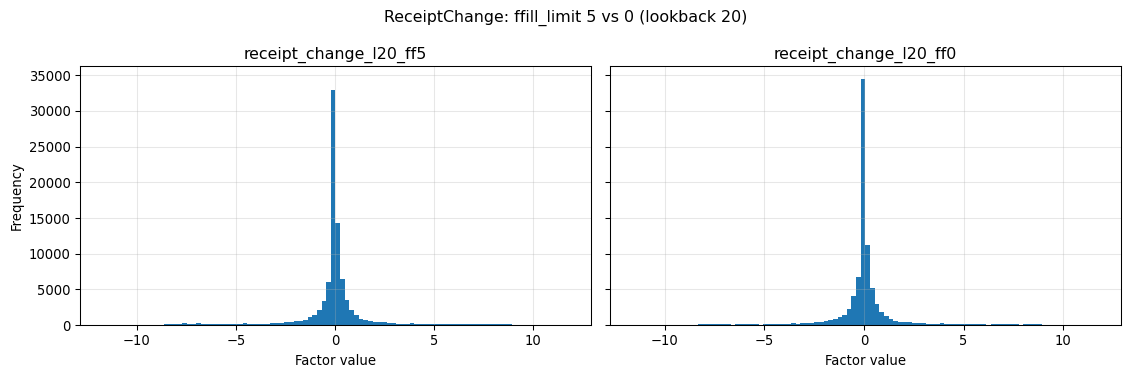

In [5]:
representative = factor_values['l20_ff5']
glance = xray.quick_glance_at(representative, print_out=True)

# 分交易所 + 覆盖率最低的品种（只列后 10 名，避免长表刷屏）。
product_coverage = representative.notna().groupby(level='product').mean()
cov_table = pd.DataFrame({'coverage': product_coverage})
cov_table['exchange'] = [
    exchange_map.get(p, '?') for p in cov_table.index]
by_exchange = cov_table.groupby('exchange')['coverage'].agg(
    ['count', 'mean', 'median', 'min'])
print('分交易所覆盖率（l20_ff5）：')
display(by_exchange.style.format('{:.2%}'))
print('覆盖率最低的 10 个品种：')
display(
    cov_table.sort_values('coverage').head(10)
    .style.format({'coverage': '{:.2%}'}))

_ = xray.plot_hist(
    factor_values['l20_ff5'],
    factor_values['l20_ff0'],
    bins=100,
    suptitle='ReceiptChange: ffill_limit 5 vs 0 (lookback 20)',
)

## 诊断组合参数扫描

对每组因子值扫描 `h = 5, 10, ..., 60`，使用截面市场中性的 `market_rank_ls` 配方，以代理成本后收益的 Sharpe 与 CAGR 评价。每个 `(variant, h)` 在 10 个调仓锚点相位上各跑一次并取平均（`offset = 0..9`；`h=5` 时 offset 5-9 与 0-4 重复、均值不变），在扫描层面缓解 rebalance timing luck。

扫描任务用 joblib（loky 后端，`n_jobs=8`，`batch_size=4`）并行分发：闭包捕获的 `dataset` / `factor_values` 经 cloudpickle 按值传给 worker，`Parallel` 保序返回，最后直接构造 `ScanResult`（`run_scan` 不参与执行，其 `error_policy='raise'` 语义由 `evaluate_mrls` 内的 cid 包装复刻）。

In [ ]:
from uuid import uuid4

from joblib import Parallel, delayed
from tqdm import tqdm

from factors.diagnostic_portfolio.robustness import _resolve_timeline
from factors.scanning import ScanResult

# 每个 (variant, h) 在 10 个调仓锚点相位上各跑一次再取平均：
# h=5 只有 5 个不同相位（offset 5-9 与 0-4 重复、均值不变，无害），
# h >= 10 时 10 个相位全部有效。在扫描层面平均相位，可以在画参数面
# 之前就压掉单锚点带来的 rebalance timing luck
# （代价是每个候选要跑 10 次诊断组合）。
ANCHOR_OFFSETS = range(0, 10)

candidate_grid = {
    'variant': list(factor_values),
    'h': range(5, 65, 5),
}
candidates = gen_candidate_grid(candidate_grid)
assert len(candidates) == 10 * 12

timeline = _resolve_timeline(dataset) # build global timeline


def evaluate_mrls(cid: str, params: Mapping[str, Any]) -> EvaluationResult:
    """运行一组截面市场中性诊断组合，对 10 个 anchor offset 取平均。"""
    try:
        signal = replace(
            presets.base_signal, values=factor_values[params['variant']])
        h = params['h']
        sharpes: list[float] = []
        cagrs: list[float] = []
        warnings_all: list[str] = []
        for offset in ANCHOR_OFFSETS:
            anchor = timeline[offset]
            rebalance = replace(presets.base_rebalance_config, interval=h,
                                anchor=anchor)
            spec = replace(presets.mrls_base_spec, rebalance=rebalance)
            runner = DiagnosticPortfolioExperimentRunner(
                signal=signal, dataset=dataset, spec=spec,
            )
            rst = runner.run()
            sharpes.append(
                float(rst.performance.loc['proxy_net', 'sharpe']))
            cagrs.append(float(rst.performance.loc['proxy_net', 'cagr']))
            warnings_all.extend(rst.warnings)
        metrics = {
            'sharpe': float(np.mean(sharpes)),
            'cagr': float(np.mean(cagrs)),
        }
        return EvaluationResult(
            metrics=metrics, warnings=tuple(warnings_all),
        )
    except Exception as e:
        # 复刻 run_scan(error_policy='raise') 的报错语义：异常带上候选 cid。
        raise RuntimeError(f'运行参数扫描 cid={cid} 失败。') from e


# joblib 的 loky 后端用 cloudpickle 按值序列化：notebook 单元格里定义、
# 闭包捕获 dataset / factor_values / timeline 的函数可以直接跨进程，
# 这一点与 robustness.py 中 ProcessPoolExecutor 要求 worker 在模块顶层
# 的约束不同。Parallel 保序返回（等价 executor.map），因此
# zip(candidates, results) 与串行版一一对应；batch_size 让闭包里的
# 大 payload（dataset + 10 条因子 Series，几十 MB）按批而非按任务传输。
task_stream = Parallel(n_jobs=8, batch_size=4, return_as='generator')(
    delayed(evaluate_mrls)(cand.cid, cand.params) for cand in candidates
)
results = list(tqdm(
    task_stream, total=len(candidates),
    desc='扫描 ReceiptChange 参数（8 进程）',
))

# 不改 run_scan：直接构造等价的 ScanResult（下游只消费
# eval_metrics / candidate_params，两者结构与 run_scan 输出一致）。
scan_result = ScanResult(
    sid=uuid4().hex,
    eval_metrics=pd.DataFrame(
        {c.cid: r.metrics for c, r in zip(candidates, results)}).T,
    candidate_params=pd.DataFrame(
        [c.params for c in candidates], index=[c.cid for c in candidates]),
    errors=None,
    warnings={c.cid: r.warnings for c, r in zip(candidates, results)},
)


## 结果排名：最佳候选与两端

只看排名的两端：Top 10 说明机制在哪里最强，Last 10 说明参数选择不当时信号衰减到什么程度（防止只被最优值吸引）。完整 120 行不打印；另附 h × variant 的 Sharpe 全景表，检查相位平均后是否仍有跳变。

In [7]:
variant_meta = diagnostics_table.reset_index()[[
    'variant', 'lookback', 'ffill_limit',
]].copy()
scan_table = pd.concat(
    [scan_result.candidate_params, scan_result.eval_metrics], axis=1,
).join(variant_meta.set_index('variant'), on='variant')
scan_table.index.name = 'candidate_id'
assert len(scan_table) == 120

ranking = scan_table.sort_values(['sharpe', 'cagr'], ascending=False)
best_candidate = ranking.iloc[0]
print('最佳候选：')
display(best_candidate.to_frame('value'))
print('Sharpe 排名前 10：')
display(ranking.head(10).round(4))
print('Sharpe 排名末 10：')
display(ranking.tail(10).round(4))
print('各变体 Sharpe 随 h 的完整走势（10 相位均值，检查跳变是否已被平滑）：')
display(
    scan_table.pivot(index='h', columns='variant', values='sharpe')
    .round(3))




最佳候选：


,value
variant,l5_ff0
h,5
sharpe,1.220011
cagr,0.051292
lookback,5
ffill_limit,0


Sharpe 排名前 10：


,variant,h,sharpe,cagr,lookback,ffill_limit
candidate_id,,,,,,
cand_0000,l5_ff0,5,1.2200,0.0513,5,0
cand_0012,l5_ff5,5,1.1745,0.0482,5,5
cand_0001,l5_ff0,10,0.9951,0.0421,5,0
cand_0013,l5_ff5,10,0.9817,0.0404,5,5
cand_0096,l60_ff0,5,0.9495,0.0385,60,0
cand_0108,l60_ff5,5,0.8943,0.0355,60,5
cand_0036,l10_ff5,5,0.8927,0.0368,10,5
cand_0097,l60_ff0,10,0.8812,0.0357,60,0
cand_0024,l10_ff0,5,0.8703,0.0371,10,0


Sharpe 排名末 10：


,variant,h,sharpe,cagr,lookback,ffill_limit
candidate_id,,,,,,
cand_0008,l5_ff0,45,0.2885,0.0120,5,0
cand_0020,l5_ff5,45,0.2548,0.0100,5,5
cand_0069,l20_ff5,50,0.2501,0.0094,20,5
cand_0046,l10_ff5,55,0.2310,0.0086,10,5
cand_0021,l5_ff5,50,0.2149,0.0082,5,5
cand_0023,l5_ff5,60,0.2140,0.0082,5,5
cand_0009,l5_ff0,50,0.2040,0.0080,5,0
cand_0011,l5_ff0,60,0.1875,0.0073,5,0
cand_0033,l10_ff0,50,-0.0301,-0.0021,10,0


各变体 Sharpe 随 h 的完整走势（10 相位均值，检查跳变是否已被平滑）：


variant,l10_ff0,l10_ff5,l20_ff0,l20_ff5,l40_ff0,l40_ff5,l5_ff0,l5_ff5,l60_ff0,l60_ff5
h,,,,,,,,,,
5,0.870,0.893,0.767,0.636,0.588,0.549,1.220,1.175,0.949,0.894
10,0.732,0.737,0.657,0.557,0.546,0.447,0.995,0.982,0.881,0.849
15,0.763,0.654,0.585,0.462,0.541,0.418,0.822,0.791,0.753,0.708
20,0.480,0.418,0.462,0.375,0.433,0.393,0.643,0.641,0.522,0.474
25,0.488,0.462,0.439,0.407,0.633,0.523,0.762,0.779,0.646,0.630
30,0.740,0.710,0.521,0.394,0.782,0.764,0.750,0.759,0.640,0.579
35,0.453,0.479,0.584,0.522,0.777,0.787,0.664,0.655,0.751,0.746
40,0.666,0.593,0.500,0.461,0.552,0.523,0.495,0.530,0.517,0.504
45,0.681,0.597,0.421,0.350,0.446,0.425,0.289,0.255,0.702,0.711


## 可视化 A：Sharpe 热力图

左右两图分别为 `ffill_limit=0` 与 `ffill_limit=5`；横轴是流量窗口 `lookback`，纵轴是持有期 `h`。所有子图共享对称色标，格子内为代理成本后 Sharpe（10 个调仓相位的均值）。图中文字使用英文以避免 glyph warning。

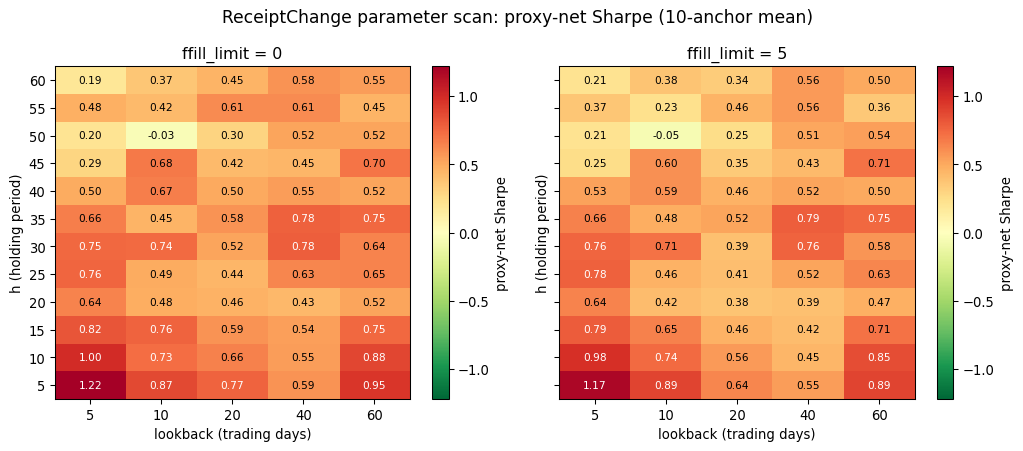

In [8]:
plot_data = scan_table.reset_index(drop=False).copy()
lookback_order = [str(x) for x in LOOKBACKS]
h_order = list(range(5, 65, 5))

vabs = float(np.nanmax(np.abs(plot_data['sharpe'].to_numpy())))
vabs = max(vabs, 1e-9)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, ffill_limit in zip(axes, FFILLS):
    subset = plot_data[plot_data['ffill_limit'] == ffill_limit]
    heat = (
        subset.pivot(index='h', columns='lookback', values='sharpe')
        .reindex(index=h_order, columns=LOOKBACKS)
    )
    image = ax.imshow(
        heat.to_numpy(), aspect='auto', origin='lower', cmap='RdYlGn_r',
        vmin=-vabs, vmax=vabs,
    )
    ax.set_xticks(range(len(LOOKBACKS)), lookback_order)
    ax.set_yticks(range(len(h_order)), h_order)
    ax.set_xlabel('lookback (trading days)')
    ax.set_ylabel('h (holding period)')
    ax.set_title(f'ffill_limit = {ffill_limit}')
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            value = heat.iat[i, j]
            if pd.isna(value):
                continue
            color = 'black' if abs(value) < 0.6 * vabs else 'white'
            ax.text(
                j, i, f'{value:.2f}', ha='center', va='center',
                fontsize=8, color=color,
            )
    fig.colorbar(image, ax=ax, label='proxy-net Sharpe')

fig.suptitle('ReceiptChange parameter scan: proxy-net Sharpe'
             ' (10-anchor mean)', fontsize=13)
fig.tight_layout()
plt.show()

## 可视化 B：Sharpe 与持有期

同一变体在不同持有期下的 Sharpe 走势（10 相位均值），用于判断结果对调仓频率的敏感度。单锚点尖峰已在扫描层面被相位平均大幅压低，走势主要反映持有期本身的结构；相邻 h 间 0.1-0.2 量级的残余摆动主要是相位估计噪声，不宜过度解读。

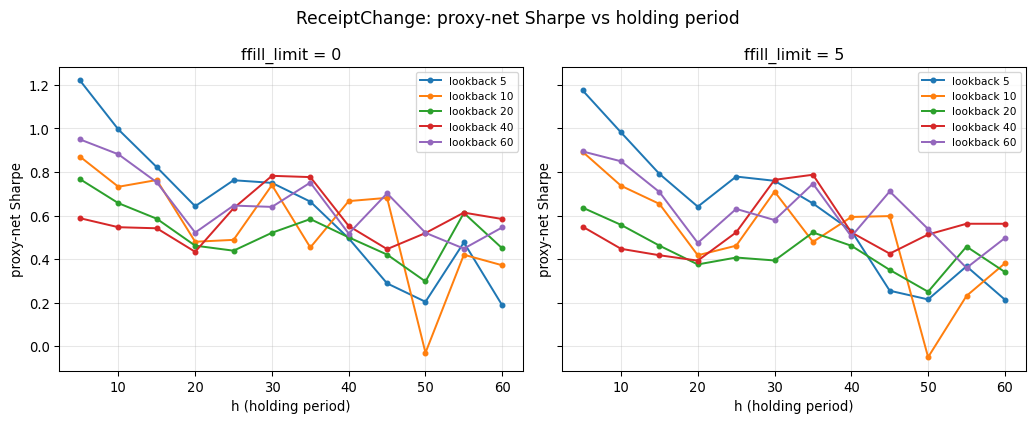

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
colors = {
    5: '#1f77b4', 10: '#ff7f0e', 20: '#2ca02c',
    40: '#d62728', 60: '#9467bd',
}
for ax, ffill_limit in zip(axes, FFILLS):
    for lookback in LOOKBACKS:
        variant = f'l{lookback}_ff{ffill_limit}'
        subset = (
            scan_table[scan_table['variant'] == variant]
            .sort_values('h')
        )
        ax.plot(
            subset['h'], subset['sharpe'],
            label=f'lookback {lookback}',
            color=colors[lookback], marker='o', markersize=3.5,
        )
    ax.set_xlabel('h (holding period)')
    ax.set_ylabel('proxy-net Sharpe')
    ax.set_title(f'ffill_limit = {ffill_limit}')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle('ReceiptChange: proxy-net Sharpe vs holding period', fontsize=13)
fig.tight_layout()
plt.show()

## 可视化 C：Top-15 候选条形图（排名视角）

热力图与折线图回答"结构"，条形图回答"排名"：哪些参数组合真正进入了头部，头部之间的差距是连续的还是断崖的。条形按 Sharpe 着色，标注 CAGR，用参数标签 `l{lookback}_ff{ffill} | h={h}` 标识每个候选。

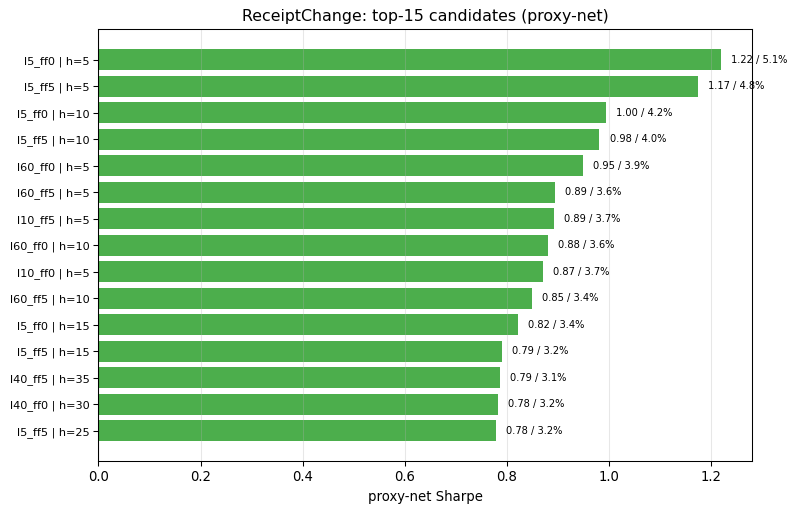

In [10]:
top15 = ranking.head(15).copy()
labels = [
    f"l{int(row.lookback)}_ff{int(row.ffill_limit)} | h={int(row.h)}"
    for _, row in top15.iterrows()
]
colors = np.where(top15['sharpe'] >= 0, '#2ca02c', '#d62728')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
bars = ax.barh(
    np.arange(len(top15))[::-1], top15['sharpe'], color=colors, alpha=0.85)
ax.set_yticks(np.arange(len(top15))[::-1], labels, fontsize=8.5)
ax.set_xlabel('proxy-net Sharpe')
ax.set_title('ReceiptChange: top-15 candidates (proxy-net)')
for y, (_, row) in zip(np.arange(len(top15))[::-1], top15.iterrows()):
    ax.text(
        row.sharpe + (0.02 if row.sharpe >= 0 else -0.02), y,
        f"{row.sharpe:.2f} / {row.cagr:.1%}",
        va='center',
        ha='left' if row.sharpe >= 0 else 'right',
        fontsize=7.5,
    )
ax.grid(True, axis='x', alpha=0.3)
ax.axvline(0, color='black', linewidth=0.8)
fig.tight_layout()
plt.show()

## 样本内结果摘要

- 10 相位均值的总排名第一候选为 `l5_ff0 / h=5`（代理成本后 Sharpe `1.22`，CAGR `5.13%`），第二名 `l5_ff5 / h=5`（`1.17`，`4.82%`）；前 10 名全部是 `h ∈ {5, 10}` 的短持有期候选，来自 `l5`、`l60`、`l10` 三个家族——旧单锚点扫描中散落在 `h=15/25/40/45` 的孤立尖峰不再出现在头部。
- 持有期结构从"各家族在特定 h 冒尖"变为清晰的衰减形态，衰减速度由流量窗口决定：`l5` 家族从 h=5 的约 `1.2` 逐级衰减，h ≥ 40 后落到 `0.2-0.5`（短窗冲击被市场消化得快，持有越久信号越失效）；`l60` 家族在 h=5/10 即有 `0.85-0.95`，此后维持 `0.45-0.75` 的平台（长窗信号更持久）；`l40` 家族在 `h=30/35` 有参数面上唯一残留的中持有期凸起（约 `0.78`）；`l10 / l20` 家族除 h=5/10 外多数 < `0.7`，且随 h 波动大，`l10` 在 `h=50` 双双转负（`-0.03 / -0.05`）。
- 相位平均的作用可以直接对比验证：单锚点下 `l5_ff0` 在 h=10/15/20 的读数是 `0.70 / 1.13 / 0.45`（h=15 孤立尖峰），10 相位均值后变为 `1.00 / 0.82 / 0.64` 的平滑衰减——旧参数面上的中持有期尖峰大部分是调仓时点运气（rebalance timing luck）。
- 残余相位噪声仍可见：10 相位均值的标准误约 `±0.08`（相位 std ≈ `0.25`），相邻 h 间 `0.1-0.2` 的摆动（如 `l60` 家族 `0.52 ↔ 0.75` 的锯齿、`l5` 在 h=55 的回弹）与该量级一致；跨候选比较时应看邻域平台，而非单个格子。
- `ffill_limit` 不是主导参数：`l5` 家族 ff0 与 ff5 的 Sharpe 差异除个别持有期（h=55，差 `0.11`）外均在 `0.05` 以内（h=5：`1.220` vs `1.175`）；对覆盖率的影响约 4 个百分点（`l5`：88.2% vs 84.3%）。
- 信号分布两侧基本对称（正 35.4% vs 负 33.6%），17.2% 的观测恰好为 0（窗口内仓单不变），尾部极值约 ±11.7：注册/注销流量是稀疏的大冲击，截面 rank 配方与这种分布天然适配。


## 解释边界

- 以上结果是同一样本内的机制比较，最优候选使用完整样本选出，不能直接视为样本外结论；后续应以时间切分或 walk-forward 实验验证稳定性。
- 扫描指标是 10 个调仓相位（`offset 0-9`）的均值：它把单锚点读数的运气压低了一个量级（`l5_ff0/h=15` 单锚点 `1.13`、邻域 `0.70/0.45`；相位均值后 `0.82`、与 `1.00/0.64` 平滑衔接），但不等于完整的相位分布检验。10 相位均值仍带约 `±0.08` 的标准误，参数面上 `0.1-0.2` 量级的相邻锯齿（`l60` 家族尤为明显）大部分与该噪声一致，比较候选时应看邻域平台而非单个格子；如需量化单个候选的相位分散度，应回到 `examine_rebalance_timing_luck` 做完整的相位扫描。
- 仓单是"已注册、可交割凭证"，不是社会总库存。`ReceiptChange` 刻画的是可交割供给的**流量**冲击，只解释交割月附近的供给约束，不应等同于产业库存周期信号；与仓单**水平**类信号（`SeasonalReceiptScarcity`，慢变量、季节调整）是互补关系，而非替代。
- 覆盖率不对称是本实验主要的数据边界：CZCE 仓单 2018-01-02 起才可获取（这决定了样本起点）；DCE 分所平均覆盖率约 69%，覆盖率最低的品种依次是 BB（4%）、JM（12%）、RR（29%）、WH（29%，CZCE）、B（32%）等——与因子 docstring 预期"P、J 到 2021 年才稳定日频"略有出入，实际最差的品种需以数据为准；GFEX 品种上市晚、样本短。截面构成随时间变化，跨变体、跨时期比较 Sharpe 时必须同时看覆盖率。
- `ffill_limit=5` 最多会跨 5 个交易日伪造"仓单水平不变"，可能稀释真实的注销/注册冲击；本实验中 `ff=0` 与 `ff=5` 的 Sharpe 差异普遍在 0.05 以内，说明该参数不是结果的主导因素。
- `market_rank_ls` 是截面市场中性配方：剥离了整体市场与板块方向，只保留品种间的相对强弱；它不能回答"持有该品种多头方向是否赚钱"。
- 代理成本按单边 `3e-5` 费率估算，不含保证金、滑点与冲击成本；真实执行环境下结论可能弱化。
- 参数轴只覆盖 `lookback` 与 `ffill_limit`；未做剔除低覆盖品种（如 BB、JM）、剔除单一交易所或改变 `min_cross_section_size` 的敏感性测试。`h=5` 只有 5 个不同相位（offset 5-9 为重复相位，均值不变），`h > 60` 的区域未纳入扫描。
